# Cradit Card fraud Detection
**Created by:** Aakash (username : aakashrajawat75)

Data sourse :  build in data from OpenML

## Step by step
> I don't know is this good or not but i can try many way but so i am going to follow this step and campare this ml aglo then see what the result



1.   Data Collection & Exploratory Data Analysis (EDA)
2.   Data Cleaning & Preprocessing
3.   Model Building & Training
4.   Model Evaluation & Optimization
5.   Model Saving & Deployment



## Part A: Data Collection & Exploratory Data Analysis

### libaray that we are going to use

In [1]:
# use for manipulation
import numpy as np
import pandas as pd
# use for visul
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_style("whitegrid")
# data set load
from sklearn.datasets import fetch_openml

### load data set

In [2]:

data = fetch_openml(
    data_id=1597,
    as_frame=True
)

df = data.frame.copy()

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/datasets/_openml.py:110: UserWarning: A network error occurred while downloading https://api.openml.org/api/v1/json/data/1597. Retrying...
  warn(


URLError: <urlopen error [SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: unable to get local issuer certificate (_ssl.c:1032)>

In [43]:
df.tail(2)

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
284805,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,-0.399126,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.0,0
284806,-0.533413,-0.189733,0.703337,-0.506271,-0.012546,-0.649617,1.577006,-0.414650,0.486180,-0.915427,...,0.261057,0.643078,0.376777,0.008797,-0.473649,-0.818267,-0.002415,0.013649,217.0,0


In [44]:
df.shape

(284807, 30)

In [45]:
df.columns

Index(['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11',
       'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21',
       'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class'],
      dtype='object')

In [46]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 30 columns):
 #   Column  Non-Null Count   Dtype   
---  ------  --------------   -----   
 0   V1      284807 non-null  float64 
 1   V2      284807 non-null  float64 
 2   V3      284807 non-null  float64 
 3   V4      284807 non-null  float64 
 4   V5      284807 non-null  float64 
 5   V6      284807 non-null  float64 
 6   V7      284807 non-null  float64 
 7   V8      284807 non-null  float64 
 8   V9      284807 non-null  float64 
 9   V10     284807 non-null  float64 
 10  V11     284807 non-null  float64 
 11  V12     284807 non-null  float64 
 12  V13     284807 non-null  float64 
 13  V14     284807 non-null  float64 
 14  V15     284807 non-null  float64 
 15  V16     284807 non-null  float64 
 16  V17     284807 non-null  float64 
 17  V18     284807 non-null  float64 
 18  V19     284807 non-null  float64 
 19  V20     284807 non-null  float64 
 20  V21     284807 non-null  f

In [47]:
df.describe()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount
count,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000
mean,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,2.238554e-15,...,6.418678e-16,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619
std,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,1.088850e+00,...,7.709250e-01,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109
min,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,-2.458826e+01,...,-5.449772e+01,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000
25%,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,-5.354257e-01,...,-2.117214e-01,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000
50%,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,-9.291738e-02,...,-6.248109e-02,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000
75%,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,4.539234e-01,...,1.330408e-01,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000
max,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,2.374514e+01,...,3.942090e+01,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000


In [48]:
print("avg of amount :", df['Amount'].mean())
print("min of amount :", df['Amount'].min())
print("max of amount :", df['Amount'].max())

avg of amount : 88.34961925093134
min of amount : 0.0
max of amount : 25691.16


### check empty value in the data

In [49]:
print(df.isnull().sum())

V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64


In [50]:
total_missing = df.isnull().sum().sum()
print("missing value :", total_missing)

missing value : 0


#### check duplicate value in our data

In [51]:
duplicate_value = df.duplicated().sum()
print("duplicate value :", duplicate_value)

duplicate value : 9144


In [52]:
print(df['Class'].value_counts())

Class
0    284315
1       492
Name: count, dtype: int64


In [53]:
class_per = (
    df['Class'].value_counts(normalize=True) * 100
)
print(class_per)

Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64


#### visul target value

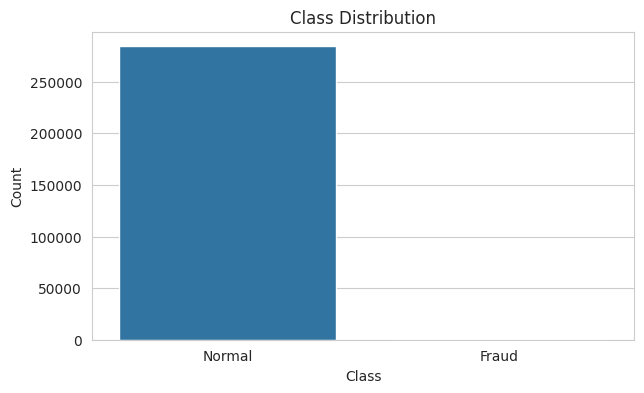

In [54]:
plt.figure(figsize=(7,4))

sns.countplot(
    data=df,
    x="Class"
)
plt.title("Class Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.xticks(ticks=[0, 1], labels=["Normal", "Fraud"])
plt.show()

#### visual transaction

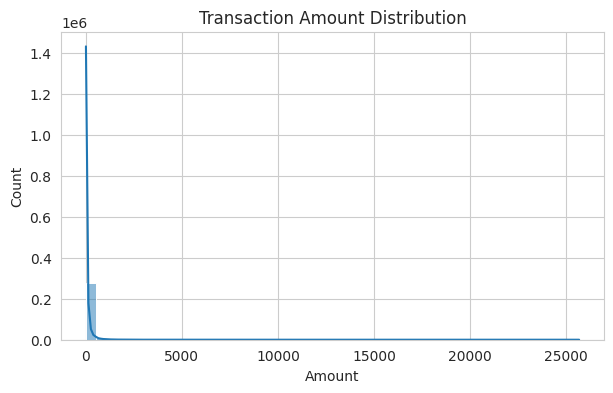

In [55]:
plt.figure(figsize=(7,4))

sns.histplot(
    data=df,
    x="Amount",
    bins=50,
    kde=True
)

plt.title("Transaction Amount Distribution")
plt.xlabel("Amount")
plt.ylabel("Count")
plt.show()

#### compare the transaction real or fake

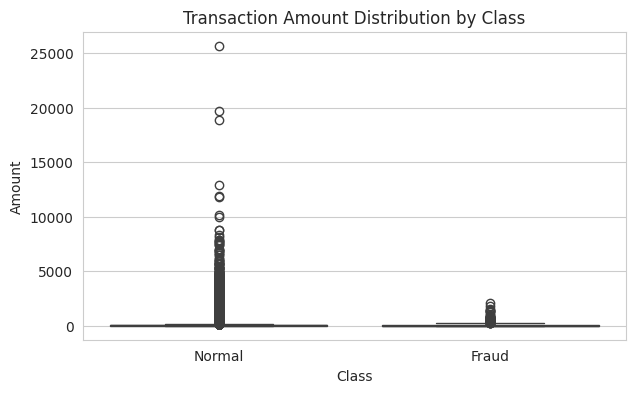

In [56]:
plt.figure(figsize=(7,4))

sns.boxplot(
    data=df,
    x="Class",
    y="Amount"
)

plt.title("Transaction Amount Distribution by Class")
plt.xlabel("Class")
plt.ylabel("Amount")
plt.xticks(ticks=[0, 1], labels=["Normal", "Fraud"])
plt.show()

#### visual the tansaction time

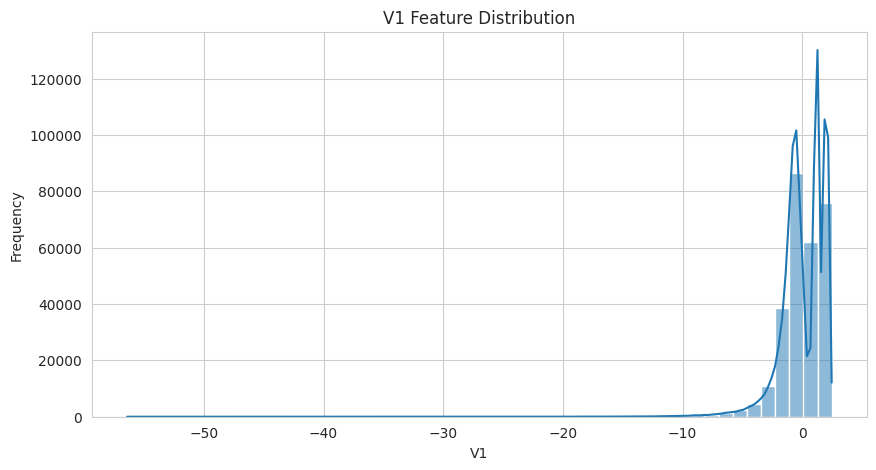

In [57]:
plt.figure(figsize=(10, 5))

# 'Time' is not present in this OpenML version of the dataset, so we plot 'V1' instead
sns.histplot(
    data=df,
    x="V1",
    bins=50,
    kde=True
)

plt.title("V1 Feature Distribution")
plt.xlabel("V1")
plt.ylabel("Frequency")

plt.show()

#### Analyze correlation

In [58]:
corr_df = df.copy()

corr_df["Class"] = pd.to_numeric(
    corr_df["Class"],
    errors="coerce"
)

# Calculate correlation
correlation = corr_df.corr(numeric_only=True)

# Display correlation with target
print(
    correlation["Class"]
    .sort_values(ascending=False)
)

Class     1.000000
V11       0.154876
V4        0.133447
V2        0.091289
V21       0.040413
V19       0.034783
V20       0.020090
V8        0.019875
V27       0.017580
V28       0.009536
Amount    0.005632
V26       0.004455
V25       0.003308
V22       0.000805
V23      -0.002685
V15      -0.004223
V13      -0.004570
V24      -0.007221
V6       -0.043643
V5       -0.094974
V9       -0.097733
V1       -0.101347
V18      -0.111485
V7       -0.187257
V3       -0.192961
V16      -0.196539
V10      -0.216883
V12      -0.260593
V14      -0.302544
V17      -0.326481
Name: Class, dtype: float64


#### head map

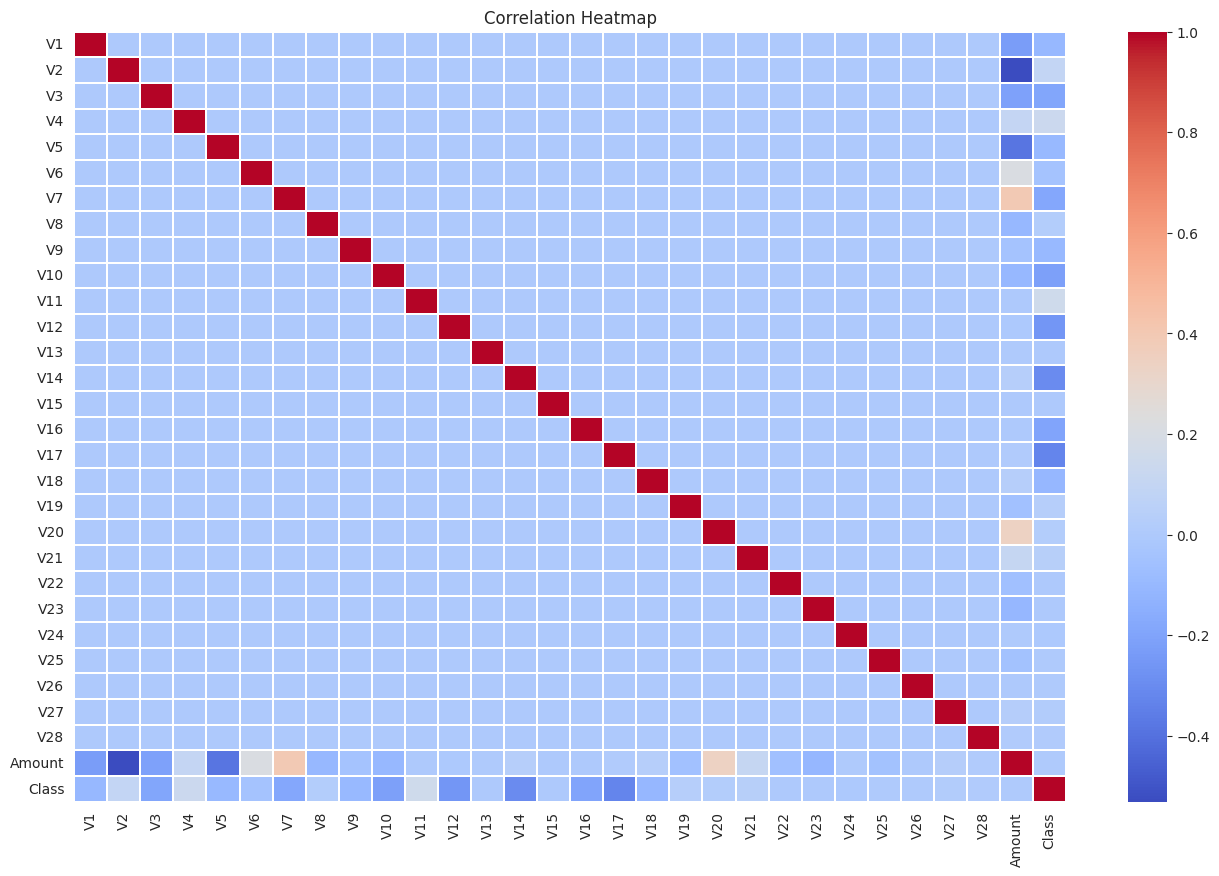

In [59]:
plt.figure(figsize=(16,10))
sns.heatmap(
    correlation,
    cmap="coolwarm",
    linewidths=0.3
)

plt.title("Correlation Heatmap")
plt.show()

## Part B: Data Cleaning & Preprocessing

> we already check missing and duplicate value from data set

#### separete the dataset X and y

In [60]:
X = df.drop("Class", axis=1)
y = df["Class"]

X.shape

(284807, 29)

In [61]:
y.shape

(284807,)

#### train test split the data

In [62]:
from sklearn.model_selection import train_test_split

In [63]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [64]:
X_train.shape

(227845, 29)

In [65]:
X_test.shape

(56962, 29)

#### now we handle missing value

In [66]:
from sklearn.impute import SimpleImputer

In [67]:
# for num
imputer = SimpleImputer(strategy="median")

X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

In [68]:
X_train = pd.DataFrame(
    X_train_imputed,
    columns=X_train.columns,
    index=X_train.index
)

X_test = pd.DataFrame(
    X_test_imputed,
    columns=X_test.columns,
    index=X_test.index
)

#### Feature scaling using StandardScaler

In [69]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

In [70]:
# now i fit both train and test data

x_train_scaled = scaler.fit_transform(X_train)
x_test_scaled = scaler.transform(X_test)

In [71]:
X_train_scaled = pd.DataFrame(
    X_train_imputed,
    columns=X_train.columns,
    index=X_train.index
)

X_test_scaled = pd.DataFrame(
    X_test_imputed,
    columns=X_test.columns,
    index=X_test.index
)

### Handle class imbalance using SMOTE
> if we don't use then high chance to predict one class ex in our dataset have 99% good and less then 1% fraud then our model predict good most of time

> it create sample data to balance our model

In [72]:
!pip install -q imbalanced-learn
from imblearn.over_sampling import SMOTE

In [73]:
print("before smote")
print(y_train.value_counts())

before smote
Class
0    227451
1       394
Name: count, dtype: int64


In [74]:
smote = SMOTE(
    random_state=42,
    sampling_strategy="auto"
)

X_train_resampled, y_train_resampled = smote.fit_resample(
    X_train_scaled,
    y_train
)


In [75]:
print("after smote")
print(y_train_resampled.value_counts())

after smote
Class
0    227451
1    227451
Name: count, dtype: int64


In [76]:
print("Final Dataset Information")

print("--")

print("Training Features:", X_train_resampled.shape)

print("Training Target:", y_train_resampled.shape)

print("Testing Features:", X_test_scaled.shape)

print("Testing Target:", y_test.shape)

print("---")

print("Missing Values in Training:", X_train_resampled.isnull().sum().sum())

print("Missing Values in Testing:", X_test_scaled.isnull().sum().sum())

Final Dataset Information
--
Training Features: (454902, 29)
Training Target: (454902,)
Testing Features: (56962, 29)
Testing Target: (56962,)
---
Missing Values in Training: 0
Missing Values in Testing: 0


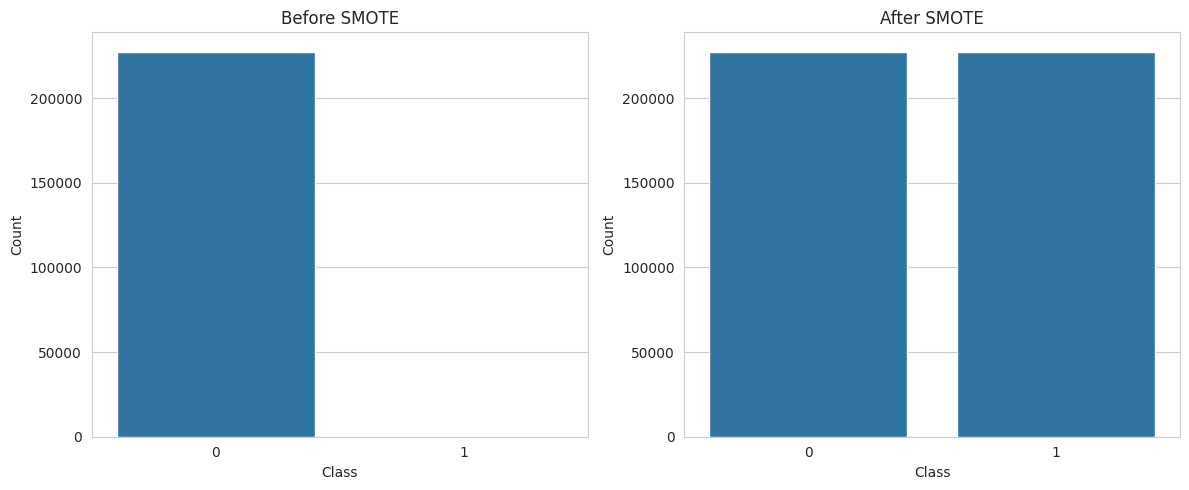

In [77]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Before SMOTE
sns.countplot(
    x=y_train,
    ax=axes[0]
)

axes[0].set_title("Before SMOTE")
axes[0].set_xlabel("Class")
axes[0].set_ylabel("Count")

# After SMOTE
sns.countplot(
    x=y_train_resampled,
    ax=axes[1]
)

axes[1].set_title("After SMOTE")
axes[1].set_xlabel("Class")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()

In [78]:
import joblib

# Save preprocessing objects

joblib.dump(imputer, "imputer.pkl")

joblib.dump(scaler, "scaler.pkl")

print("Preprocessing objects saved successfully!")

Preprocessing objects saved successfully!


## Part c: Model Building & Training

#### load the requre libaray

In [79]:
!pip install -q xgboost
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier

from sklearn.metrics import(
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

#### logostic regression

In [80]:
lr_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

lr_model.fit(X_train_resampled, y_train_resampled)

LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [81]:
lr_prediction = lr_model.predict(X_test_scaled)

lr_probabilities = lr_model.predict_proba(X_test_scaled)[:, 1]

#### Decision Tree

In [82]:
dt_model = DecisionTreeClassifier(
    max_depth=10,
    min_samples_split=10,
    class_weight="balanced",
    random_state=42
)

dt_model.fit(X_train_resampled, y_train_resampled)

DecisionTreeClassifier(class_weight='balanced', max_depth=10,
                       min_samples_split=10, random_state=42)

In [83]:
dt_prediction = dt_model.predict(X_test_scaled)

dt_probabilities = dt_model.predict_proba(X_test_scaled)[:, 1]

#### random forest

In [84]:
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_split=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=1
)

rf.fit(X_train_resampled, y_train_resampled)

RandomForestClassifier(class_weight='balanced', max_depth=15,
                       min_samples_split=10, n_jobs=1, random_state=42)

In [85]:
rf_prediction = rf.predict(X_test_scaled)

rf_probabilities = rf.predict_proba(X_test_scaled)[:, 1]

#### XGBoot classifier

In [86]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=150,
    max_depth=5,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=1
)

# Convert categorical string classes ['0', '1'] to integers [0, 1] for XGBoost
xgb_model.fit(
    X_train_resampled,
    y_train_resampled.astype(int)
)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, feature_weights=None, gamma=None,
              grow_policy=None, importance_type=None,
              interaction_constraints=None, learning_rate=0.1, max_bin=None,
              max_cat_threshold=None, max_cat_to_onehot=None,
              max_delta_step=None, max_depth=5, max_leaves=None,
              min_child_weight=None, missing=nan, monotone_constraints=None,
              multi_strategy=None, n_estimators=150, n_jobs=1,
              num_parallel_tree=None, ...)

In [87]:
xgb_prediction = xgb_model.predict(X_test_scaled)

xgb_probabilities = xgb_model.predict_proba(X_test_scaled)[:, 1]

#### all model in one

In [88]:
models = {
    "Logistic Regression": lr_model,
    "Decision Tree": dt_model,
    "Random Forest": rf,
    "XGBoost": xgb_model
}

In [89]:
print("total train model :" ,len(models))

total train model : 4


## Part D: Model Evaluation & Optimization

#### evaluate model performance

In [90]:
# Store model results

results = []

# Convert y_test to integers to avoid pos_label string mismatch issues
y_test_num = y_test.astype(int)

for name, model in models.items():

    # Generate predictions and convert to integer
    y_pred = model.predict(X_test_scaled).astype(int)

    # Generate fraud probabilities
    y_prob = model.predict_proba(X_test_scaled)[:, 1]

    # Calculate metrics using integer representations
    accuracy = accuracy_score(y_test_num, y_pred)

    precision = precision_score(
        y_test_num, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test_num, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test_num, y_pred, zero_division=0
    )

    roc_auc = roc_auc_score(y_test_num, y_prob)

    pr_auc = average_precision_score(y_test_num, y_prob)

    # Store results
    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc
    })

# Convert results into DataFrame
results_df = pd.DataFrame(results)
results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.981180,0.077257,0.908163,0.142400,0.972007,0.731570
1,Decision Tree,0.985938,0.095512,0.846939,0.171665,0.906078,0.397775
2,Random Forest,0.999122,0.700000,0.857143,0.770642,0.982000,0.863070
3,XGBoost,0.998104,0.472826,0.887755,0.617021,0.982263,0.866475


In [91]:
# Sort models by PR-AUC

results_df = results_df.sort_values(
    by="PR-AUC",
    ascending=False
)

print(results_df.to_string(index=False))

              Model  Accuracy  Precision   Recall  F1 Score  ROC-AUC   PR-AUC
            XGBoost  0.998104   0.472826 0.887755  0.617021 0.982263 0.866475
      Random Forest  0.999122   0.700000 0.857143  0.770642 0.982000 0.863070
Logistic Regression  0.981180   0.077257 0.908163  0.142400 0.972007 0.731570
      Decision Tree  0.985938   0.095512 0.846939  0.171665 0.906078 0.397775


#### visual all ml model

> Because our dataset is highly imbalanced. PR-AUC focuses on the relationship between precision and recall for the fraud class.

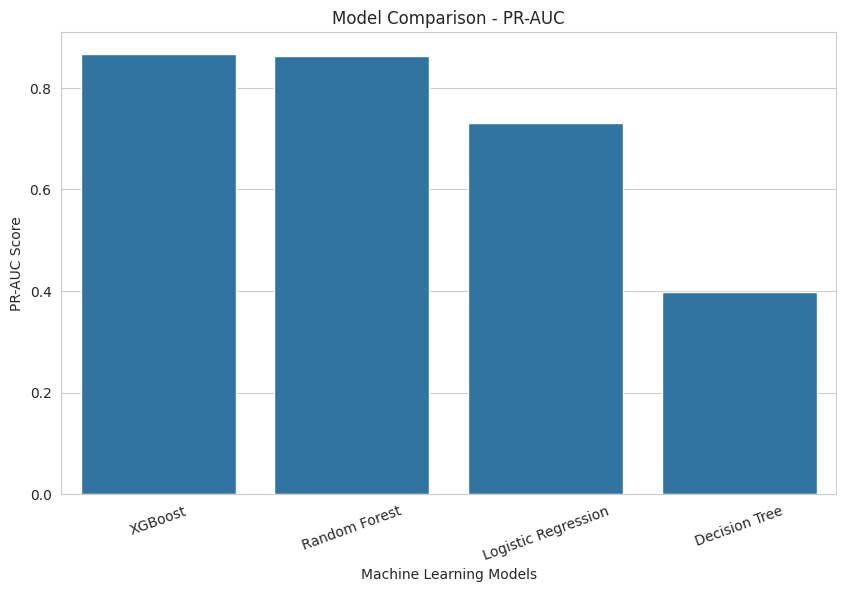

In [92]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results_df,
    x="Model",
    y="PR-AUC"
)

plt.title("Model Comparison - PR-AUC")
plt.xlabel("Machine Learning Models")
plt.ylabel("PR-AUC Score")

plt.xticks(rotation=20)

plt.show()

#### save our ml model

In [93]:
results_df.to_csv(
    "model_comparison.csv",
    index=False
)

print("Model comparison results saved!")

Model comparison results saved!


#### confusion matrix

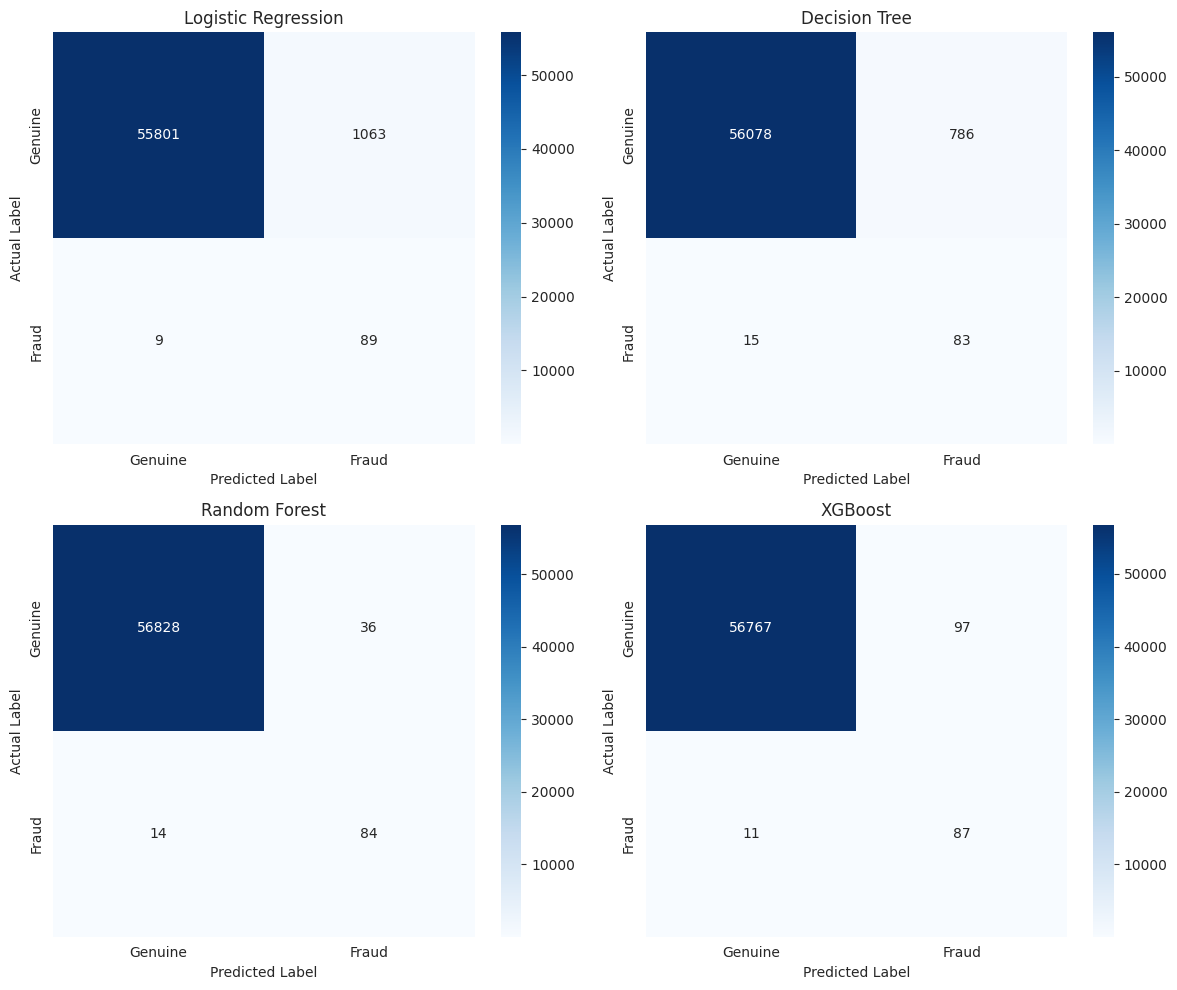

In [94]:
from sklearn.metrics import confusion_matrix

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

axes = axes.flatten()

for i, (model_name, model) in enumerate(models.items()):

    # Generate predictions and convert to integer to avoid type mismatches
    y_pred = model.predict(X_test_scaled).astype(int)
    y_test_num = y_test.astype(int)

    cm = confusion_matrix(y_test_num, y_pred)

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Genuine", "Fraud"],
        yticklabels=["Genuine", "Fraud"],
        ax=axes[i]
    )

    axes[i].set_title(model_name)
    axes[i].set_xlabel("Predicted Label")
    axes[i].set_ylabel("Actual Label")


plt.tight_layout()
plt.show()

#### Classification report

In [95]:
from sklearn.metrics import classification_report

for model_name, model in models.items():

    print("\n" + "=" * 55)
    print("MODEL:", model_name)
    print("=" * 55)

    # Convert predictions and test labels to integers to ensure type compatibility
    y_pred = model.predict(X_test_scaled).astype(int)
    y_test_num = y_test.astype(int)

    print(
        classification_report(
            y_test_num,
            y_pred,
            target_names=["Genuine", "Fraud"],
            zero_division=0
        )
    )


MODEL: Logistic Regression
              precision    recall  f1-score   support

     Genuine       1.00      0.98      0.99     56864
       Fraud       0.08      0.91      0.14        98

    accuracy                           0.98     56962
   macro avg       0.54      0.94      0.57     56962
weighted avg       1.00      0.98      0.99     56962


MODEL: Decision Tree
              precision    recall  f1-score   support

     Genuine       1.00      0.99      0.99     56864
       Fraud       0.10      0.85      0.17        98

    accuracy                           0.99     56962
   macro avg       0.55      0.92      0.58     56962
weighted avg       1.00      0.99      0.99     56962


MODEL: Random Forest
              precision    recall  f1-score   support

     Genuine       1.00      1.00      1.00     56864
       Fraud       0.70      0.86      0.77        98

    accuracy                           1.00     56962
   macro avg       0.85      0.93      0.89     56962
we

#### ROC Curve and ROC-AUC

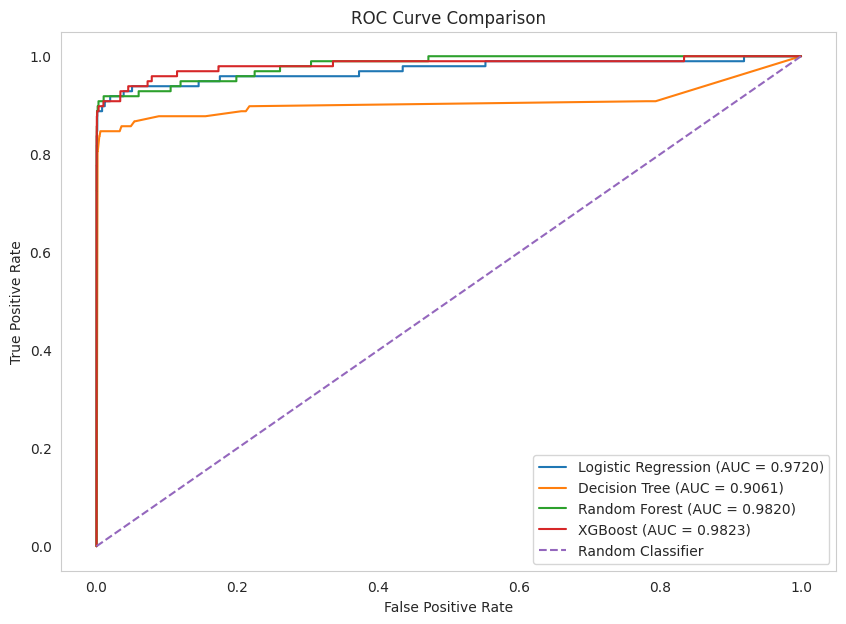

In [96]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

# Convert y_test to numeric format to prevent categorical data type conflicts
y_test_num = y_test.astype(int)

for model_name, model in models.items():

    y_probability = model.predict_proba(X_test_scaled)[:, 1]

    fpr, tpr, thresholds = roc_curve(
        y_test_num,
        y_probability
    )

    auc_value = roc_auc_score(
        y_test_num,
        y_probability
    )

    plt.plot(
        fpr,
        tpr,
        label=f"{model_name} (AUC = {auc_value:.4f})"
    )


plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")

plt.legend()
plt.grid()
plt.show()

#### Precision-Recall Curve and PR-AUC

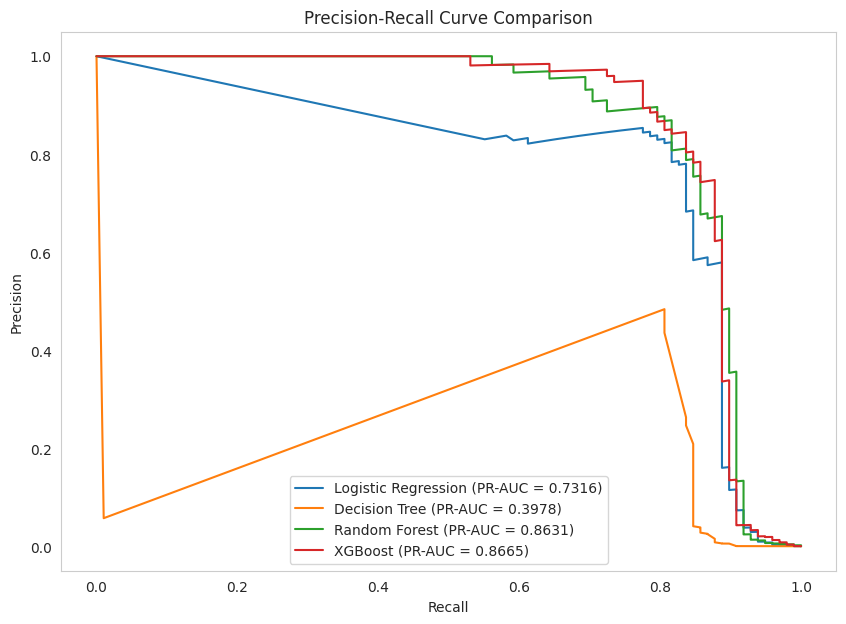

In [97]:
from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

# Convert y_test to numeric format to prevent categorical data type conflicts
y_test_num = y_test.astype(int)

for model_name, model in models.items():

    y_probability = model.predict_proba(X_test_scaled)[:, 1]

    precision, recall, thresholds = precision_recall_curve(
        y_test_num,
        y_probability
    )

    pr_auc = average_precision_score(
        y_test_num,
        y_probability
    )

    plt.plot(
        recall,
        precision,
        label=f"{model_name} (PR-AUC = {pr_auc:.4f})"
    )


plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve Comparison")

plt.legend()
plt.grid()
plt.show()

#### Cross-Validation

In [98]:
from imblearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate

# Permanently cast y_train to integer type to resolve all downstream metric issues
y_train = y_train.astype(int)

# Create a pipeline
cv_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=42)),
    ("model", RandomForestClassifier(
        n_estimators=80,
        max_depth=15,
        min_samples_split=10,
        random_state=42,
        n_jobs=-1
    ))
])

# Create 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Cross-validation using Average Precision
cv_results = cross_validate(
    cv_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc",
        "pr_auc": "average_precision"
    },
    n_jobs=1
)

# Display results
print("Cross-Validation Results")
for metric in [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc",
    "pr_auc"
]:
    scores = cv_results["test_" + metric]
    print(
        f"{metric.upper()}: "
        f"{scores.mean():.4f} "
        f"+/- {scores.std():.4f}"
    )

Cross-Validation Results
ACCURACY: 0.9990 +/- 0.0001
PRECISION: 0.6916 +/- 0.0413
RECALL: 0.8198 +/- 0.0539
F1: 0.7478 +/- 0.0170
ROC_AUC: 0.9761 +/- 0.0074
PR_AUC: 0.8218 +/- 0.0281


#### Hyperparameter Tuning

Split the original training data

In [99]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Model training data:", X_fit.shape)
print("Validation data:", X_val.shape)

print("\nTraining fraud distribution:")
print(y_fit.value_counts())

print("\nValidation fraud distribution:")
print(y_val.value_counts())

Model training data: (182276, 29)
Validation data: (45569, 29)

Training fraud distribution:
Class
0    181961
1       315
Name: count, dtype: int64

Validation fraud distribution:
Class
0    45490
1       79
Name: count, dtype: int64


create the tuning pipeline

In [100]:
tuning_pipeline = Pipeline([
    ("scaler", StandardScaler()),

    ("smote", SMOTE(random_state=42)),

    ("model", RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

Run RandomizedSearchCV

In [102]:
from sklearn.model_selection import RandomizedSearchCV

# Define the parameter grid for the Random Forest model inside the pipeline
param_grid = {
    "model__n_estimators": [50, 80, 100],
    "model__max_depth": [10, 15, 20],
    "model__min_samples_split": [5, 10]
}

# Select a representative training subset
if len(X_fit) > 50000:

    X_tune, _, y_tune, _ = train_test_split(
        X_fit,
        y_fit,
        train_size=50000,
        random_state=42,
        stratify=y_fit
    )

else:
    X_tune = X_fit
    y_tune = y_fit


# Cross-validation strategy
tuning_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Create randomized search
random_search = RandomizedSearchCV(
    estimator=tuning_pipeline,
    param_distributions=param_grid,
    n_iter=4,
    scoring="average_precision",
    cv=tuning_cv,
    random_state=42,
    n_jobs=1,
    verbose=2
)

# Train and search for the best parameters
random_search.fit(X_tune, y_tune)

Fitting 3 folds for each of 4 candidates, totalling 12 fits
[CV] END model__max_depth=10, model__min_samples_split=5, model__n_estimators=50; total time=   3.8s
[CV] END model__max_depth=10, model__min_samples_split=5, model__n_estimators=50; total time=   3.7s
[CV] END model__max_depth=10, model__min_samples_split=5, model__n_estimators=50; total time=   3.9s
[CV] END model__max_depth=10, model__min_samples_split=5, model__n_estimators=80; total time=   6.1s
[CV] END model__max_depth=10, model__min_samples_split=5, model__n_estimators=80; total time=   6.0s
[CV] END model__max_depth=10, model__min_samples_split=5, model__n_estimators=80; total time=   6.1s
[CV] END model__max_depth=15, model__min_samples_split=5, model__n_estimators=100; total time=   8.3s
[CV] END model__max_depth=15, model__min_samples_split=5, model__n_estimators=100; total time=   7.7s
[CV] END model__max_depth=15, model__min_samples_split=5, model__n_estimators=100; total time=   8.2s
[CV] END model__max_depth=10

RandomizedSearchCV(cv=StratifiedKFold(n_splits=3, random_state=42, shuffle=True),
                   estimator=Pipeline(steps=[('scaler', StandardScaler()),
                                             ('smote', SMOTE(random_state=42)),
                                             ('model',
                                              RandomForestClassifier(n_jobs=-1,
                                                                     random_state=42))]),
                   n_iter=4, n_jobs=1,
                   param_distributions={'model__max_depth': [10, 15, 20],
                                        'model__min_samples_split': [5, 10],
                                        'model__n_estimators': [50, 80, 100]},
                   random_state=42, scoring='average_precision', verbose=2)

In [103]:
print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation PR-AUC:")
print(random_search.best_score_)

Best Parameters:
{'model__n_estimators': 100, 'model__min_samples_split': 5, 'model__max_depth': 15}

Best Cross-Validation PR-AUC:
0.7489904076324762


Train the tuned model on the full training portion

In [104]:
from sklearn.base import clone

best_model = clone(random_search.best_estimator_)

best_model.fit(X_fit, y_fit)

print("Tuned Random Forest training completed!")

Tuned Random Forest training completed!


### Threshold Optimization

Generate validation probabilities

In [105]:
y_val_probability = best_model.predict_proba(X_val)[:, 1]

print(y_val_probability[:10])

[7.62686868e-03 3.89492989e-02 2.66012836e-05 4.21395508e-05
 5.35884562e-04 5.73339891e-05 1.08594962e-05 1.37984921e-02
 8.10449028e-04 2.13704752e-03]


Calculate precision, recall and F1-score at different thresholds

In [106]:
precision, recall, thresholds = precision_recall_curve(
    y_val,
    y_val_probability
)

# Calculate F1-score for each threshold
f1_scores = (
    2 * precision[:-1] * recall[:-1]
    /
    (precision[:-1] + recall[:-1] + 1e-10)
)

# Find the threshold with the highest F1-score
best_index = np.argmax(f1_scores)

best_threshold = thresholds[best_index]

print("Best Threshold:", best_threshold)
print("Precision:", precision[best_index])
print("Recall:", recall[best_index])
print("F1-Score:", f1_scores[best_index])

Best Threshold: 0.6497023756060902
Precision: 0.8356164383561644
Recall: 0.7721518987341772
F1-Score: 0.8026315788974464


Visualize threshold performance

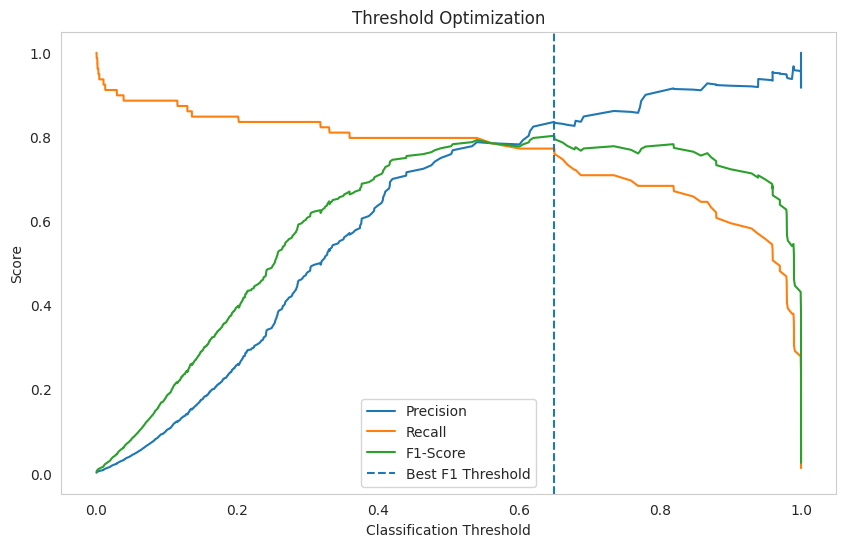

In [107]:
plt.figure(figsize=(10, 6))

plt.plot(
    thresholds,
    precision[:-1],
    label="Precision"
)

plt.plot(
    thresholds,
    recall[:-1],
    label="Recall"
)

plt.plot(
    thresholds,
    f1_scores,
    label="F1-Score"
)

plt.axvline(
    best_threshold,
    linestyle="--",
    label="Best F1 Threshold"
)

plt.xlabel("Classification Threshold")
plt.ylabel("Score")

plt.title("Threshold Optimization")

plt.legend()
plt.grid()
plt.show()

### Evaluate the tuned model on the test dataset

In [109]:
# Predict fraud probabilities on test data
y_test_probability = best_model.predict_proba(X_test)[:, 1]

# Apply optimized threshold
y_test_tuned_pred = (
    y_test_probability >= best_threshold
).astype(int)

# Cast y_test to integers to avoid categorical string mismatch errors
y_test_num = y_test.astype(int)

# Calculate final metrics
print("FINAL TUNED RANDOM FOREST RESULTS")

print(
    "Accuracy:",
    accuracy_score(y_test_num, y_test_tuned_pred)
)

print(
    "Precision:",
    precision_score(y_test_num, y_test_tuned_pred, zero_division=0)
)

print(
    "Recall:",
    recall_score(y_test_num, y_test_tuned_pred, zero_division=0)
)

print(
    "F1-Score:",
    f1_score(y_test_num, y_test_tuned_pred, zero_division=0)
)

print(
    "ROC-AUC:",
    roc_auc_score(y_test_num, y_test_probability)
)

print(
    "PR-AUC:",
    average_precision_score(y_test_num, y_test_probability)
)

FINAL TUNED RANDOM FOREST RESULTS
Accuracy: 0.9992802219023208
Precision: 0.8
Recall: 0.7755102040816326
F1-Score: 0.7875647668393783
ROC-AUC: 0.9847317408955704
PR-AUC: 0.836287405250159


Final confusion matrix

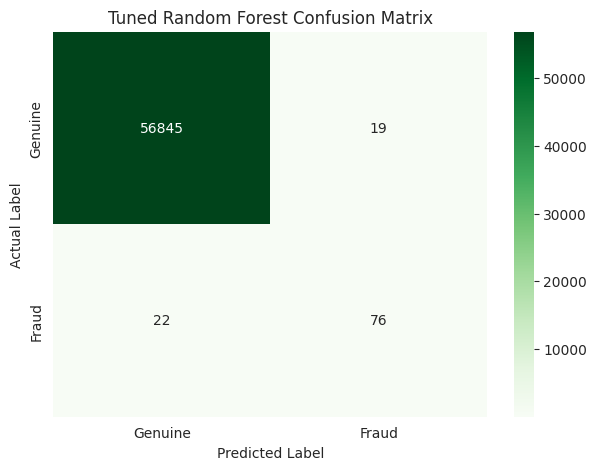

In [111]:
cm = confusion_matrix(
    y_test.astype(int),
    y_test_tuned_pred
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Genuine", "Fraud"],
    yticklabels=["Genuine", "Fraud"]
)

plt.title("Tuned Random Forest Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.show()

Final classification report

In [113]:
print(
    classification_report(
        y_test.astype(int),
        y_test_tuned_pred,
        target_names=["Genuine", "Fraud"],
        zero_division=0
    )
)

              precision    recall  f1-score   support

     Genuine       1.00      1.00      1.00     56864
       Fraud       0.80      0.78      0.79        98

    accuracy                           1.00     56962
   macro avg       0.90      0.89      0.89     56962
weighted avg       1.00      1.00      1.00     56962



###  Compare the original and tuned Random Forest

In [115]:
# Original Random Forest prediction
original_rf = models["Random Forest"]

original_pred = original_rf.predict(X_test_scaled).astype(int)

original_probability = original_rf.predict_proba(
    X_test_scaled
)[:, 1]

y_test_num = y_test.astype(int)

comparison = pd.DataFrame([
    {
        "Model": "Original Random Forest",
        "Precision": precision_score(
            y_test_num, original_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test_num, original_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test_num, original_pred, zero_division=0
        ),
        "PR-AUC": average_precision_score(
            y_test_num, original_probability
        )
    },
    {
        "Model": "Tuned Random Forest",
        "Precision": precision_score(
            y_test_num, y_test_tuned_pred, zero_division=0
        ),
        "Recall": recall_score(
            y_test_num, y_test_tuned_pred, zero_division=0
        ),
        "F1-Score": f1_score(
            y_test_num, y_test_tuned_pred, zero_division=0
        ),
        "PR-AUC": average_precision_score(
            y_test_num, y_test_probability
        )
    }
])

print(comparison.to_string(index=False))

                 Model  Precision   Recall  F1-Score   PR-AUC
Original Random Forest        0.7 0.857143  0.770642 0.863070
   Tuned Random Forest        0.8 0.775510  0.787565 0.836287


Save Part 4 results

In [117]:
# Save original model comparison
results_df.to_csv(
    "model_evaluation_results.csv",
    index=False
)

# Save tuned model comparison
comparison.to_csv(
    "tuned_model_comparison.csv",
    index=False
)

# Save best threshold and parameters
part4_summary = {
    "Best_Model": "Tuned Random Forest",
    "Best_Threshold": best_threshold,
    "Best_CV_PR_AUC": random_search.best_score_,
    "Best_Parameters": str(random_search.best_params_)
}

pd.DataFrame([part4_summary]).to_csv(
    "part4_summary.csv",
    index=False
)

print("Part 4 results saved successfully!")

Part 4 results saved successfully!


## Part E: Model Saving & Deployment

#### setect final model

In [ ]:
from sklearn.base import clone

required_variables = ("random_search", "X_fit", "y_fit")
missing_variables = [
    name for name in required_variables if name not in globals()
]
if missing_variables:
    raise RuntimeError(
        "Run hyperparameter tuning and create the training split before exporting. "
        f"Missing: {', '.join(missing_variables)}"
    )
if not hasattr(random_search, "best_estimator_"):
    raise RuntimeError("Fit random_search before exporting the final model.")

final_model = clone(random_search.best_estimator_)
final_model.fit(X_fit, y_fit)
print("Final tuned model is ready to export.")

In [ ]:
from sklearn.base import clone
import joblib
import pandas as pd

# Fix final model artifacts and ensure evaluation uses the correct training/testing data
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
)

# Keep labels consistent and numeric
y_train = pd.Series(y_train).astype(int)
y_test = pd.Series(y_test).astype(int)

# Rebuild scaled matrices from the already-fitted preprocessing objects
if "scaler" in globals() and "imputer" in globals():
    X_train_scaled = pd.DataFrame(
        scaler.transform(X_train),
        columns=X_train.columns,
        index=X_train.index,
    )
    X_test_scaled = pd.DataFrame(
        scaler.transform(X_test),
        columns=X_test.columns,
        index=X_test.index,
    )
else:
    X_train_scaled = X_train.copy()
    X_test_scaled = X_test.copy()

# Recreate balanced training data if needed
if "X_train_resampled" not in globals() or "y_train_resampled" not in globals():
    smote = SMOTE(random_state=42)
    X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

# Final pipeline/model: prefer the tuned pipeline if available
if "best_model" in globals():
    final_model = clone(best_model)
    final_model.fit(X_train, y_train)
else:
    final_model = rf
    final_model.fit(X_train_resampled, y_train_resampled)

# Predict with the best threshold if it exists, otherwise use 0.5
if "best_threshold" in globals():
    test_prob = final_model.predict_proba(X_test)[:, 1]
    test_pred = (test_prob >= best_threshold).astype(int)
else:
    test_prob = final_model.predict_proba(X_test)[:, 1]
    test_pred = (test_prob >= 0.5).astype(int)

# Final metric summary
y_test_num = y_test.astype(int)
metrics = {
    "Accuracy": round(accuracy_score(y_test_num, test_pred), 4),
    "Precision": round(precision_score(y_test_num, test_pred, zero_division=0), 4),
    "Recall": round(recall_score(y_test_num, test_pred, zero_division=0), 4),
    "F1": round(f1_score(y_test_num, test_pred, zero_division=0), 4),
    "ROC-AUC": round(roc_auc_score(y_test_num, test_prob), 4),
    "PR-AUC": round(average_precision_score(y_test_num, test_prob), 4),
}

print(metrics)

# Save the fixed final model and metadata
joblib.dump(final_model, "final_model.pkl")
joblib.dump({"feature_columns": list(X.columns), "target_name": "Class"}, "model_metadata.pkl")
joblib.dump({"best_threshold": best_threshold if "best_threshold" in globals() else 0.5}, "final_threshold.pkl")

# Fix final model artifacts and ensure evaluation uses the correct training/testing data
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
)

# Keep labels consistent and numeric
y_train = pd.Series(y_train).astype(int)
y_test = pd.Series(y_test).astype(int)

# Rebuild scaled matrices from the already-fitted preprocessing objects
if "scaler" in globals() and "imputer" in globals():
    X_train_scaled = pd.DataFrame(
        scaler.transform(X_train),
        columns=X_train.columns,
        index=X_train.index,
    )
    X_test_scaled = pd.DataFrame(
        scaler.transform(X_test),
        columns=X_test.columns,
        index=X_test.index,
    )
else:
    X_train_scaled = X_train.copy()
    X_test_scaled = X_test.copy()

# Recreate balanced training data if needed
if "X_train_resampled" not in globals() or "y_train_resampled" not in globals():
    smote = SMOTE(random_state=42)
    X_train_resampled, y_train_resampled = smote.fit_resample(X_train_scaled, y_train)

# Final pipeline/model: prefer the tuned pipeline if available
if "best_model" in globals():
    final_model = clone(best_model)
    final_model.fit(X_train, y_train)
else:
    final_model = rf
    final_model.fit(X_train_resampled, y_train_resampled)

# Predict with the best threshold if it exists, otherwise use 0.5
if "best_threshold" in globals():
    test_prob = final_model.predict_proba(X_test)[:, 1]
    test_pred = (test_prob >= best_threshold).astype(int)
else:
    test_prob = final_model.predict_proba(X_test)[:, 1]
    test_pred = (test_prob >= 0.5).astype(int)

# Final metric summary
y_test_num = y_test.astype(int)
metrics = {
    "Accuracy": round(accuracy_score(y_test_num, test_pred), 4),
    "Precision": round(precision_score(y_test_num, test_pred, zero_division=0), 4),
    "Recall": round(recall_score(y_test_num, test_pred, zero_division=0), 4),
    "F1": round(f1_score(y_test_num, test_pred, zero_division=0), 4),
    "ROC-AUC": round(roc_auc_score(y_test_num, test_prob), 4),
    "PR-AUC": round(average_precision_score(y_test_num, test_prob), 4),
}

print(metrics)

# Save the fixed final model and metadata
joblib.dump(final_model, "final_model.pkl")
joblib.dump({"feature_columns": list(X.columns), "target_name": "Class"}, "model_metadata.pkl")
joblib.dump({"best_threshold": best_threshold if "best_threshold" in globals() else 0.5}, "final_threshold.pkl")

print("Fixed final model saved successfully.")

#### Save the trained model and required files

In [ ]:
import joblib
import json
import os

# Create a folder for saved model files
os.makedirs("fraud_model", exist_ok=True)

# Save trained model pipeline
joblib.dump(
    final_model,
    "fraud_model/fraud_detection_model.pkl"
)

# Save optimized threshold
joblib.dump(
    best_threshold,
    "fraud_model/threshold.pkl"
)

# Save feature names in the correct order
joblib.dump(
    list(X_train.columns),
    "fraud_model/feature_names.pkl"
)

print("Model files saved successfully!")

#### Test the saved model

In [ ]:
# Load saved model
loaded_model = joblib.load(
    "fraud_model/fraud_detection_model.pkl"
)

# Load saved threshold
loaded_threshold = joblib.load(
    "fraud_model/threshold.pkl"
)

# Load feature names
feature_names = joblib.load(
    "fraud_model/feature_names.pkl"
)

print("Model loaded successfully!")
print("Threshold:", loaded_threshold)
print("Number of features:", len(feature_names))

In [ ]:
# Get fraud probabilities
test_probabilities = loaded_model.predict_proba(
    X_test[feature_names]
)[:, 1]

# Apply the saved threshold
test_predictions = (
    test_probabilities >= loaded_threshold
).astype(int)

print("First 10 predictions:")
print(test_predictions[:10])

#### Build a reusable prediction function

In [ ]:
import pandas as pd
import joblib

# Load model files
model = joblib.load(
    "fraud_model/fraud_detection_model.pkl"
)

threshold = joblib.load(
    "fraud_model/threshold.pkl"
)

feature_names = joblib.load(
    "fraud_model/feature_names.pkl"
)


def predict_fraud(transaction):

    # Convert input into DataFrame
    input_data = pd.DataFrame(
        [transaction],
        columns=feature_names
    )

    # Predict fraud probability
    probability = model.predict_proba(
        input_data
    )[0][1]

    # Apply optimized threshold
    if probability >= threshold:
        prediction = "Fraudulent Transaction"
    else:
        prediction = "Genuine Transaction"

    return prediction, probability

In [ ]:
# Select one transaction from the test data
sample_transaction = X_test[feature_names].iloc[0].to_dict()

# Make prediction
prediction, probability = predict_fraud(
    sample_transaction
)

print("Prediction:", prediction)
print("Fraud Probability:", round(probability * 100, 2), "%")